In [1]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

# Display first five records
print("Dataset loaded successfully!")
print(df.head())


Dataset loaded successfully!
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV Streami

In [2]:

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
print(df.describe())


Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Dataset Information

In [3]:

# Save a copy of the original dataset
df.to_csv("telco_customer_churn_original.csv", index=False)

print("Original dataset saved successfully!")


Original dataset saved successfully!


In [5]:

# WEEK 1: DATA INSPECTION

# 1. Check missing values
print("Missing Values:")
print(df.isnull().sum())

# 2. Check total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# 3. Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# 4. Check data types
print("\nData Types:")
print(df.dtypes)

# 5. Dataset information
print("\nDataset Information:")
df.info()


Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total Missing Values:
0

Duplicate Records:
0

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
P

In [6]:

# Check TotalCharges column
print("TotalCharges data type:")
print(df["TotalCharges"].dtype)

print("\nBlank TotalCharges:")
print((df["TotalCharges"].astype(str).str.strip() == "").sum())

print("\nSample TotalCharges values:")
print(df["TotalCharges"].head(15))


TotalCharges data type:
object

Blank TotalCharges:
11

Sample TotalCharges values:
0       29.85
1      1889.5
2      108.15
3     1840.75
4      151.65
5       820.5
6      1949.4
7       301.9
8     3046.05
9     3487.95
10     587.45
11      326.8
12     5681.1
13     5036.3
14    2686.05
Name: TotalCharges, dtype: object


In [7]:

# Identify rows with blank TotalCharges

blank_rows = df[
    df["TotalCharges"].astype(str).str.strip() == ""
]

print("Number of blank records:", len(blank_rows))

# Display relevant columns
print(blank_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])


Number of blank records: 11
      customerID  tenure  MonthlyCharges TotalCharges
488   4472-LVYGI       0           52.55             
753   3115-CZMZD       0           20.25             
936   5709-LVOEQ       0           80.85             
1082  4367-NUYAO       0           25.75             
1340  1371-DWPAZ       0           56.05             
3331  7644-OMVMY       0           19.85             
3826  3213-VVOLG       0           25.35             
4380  2520-SGTTA       0           20.00             
5218  2923-ARZLG       0           19.70             
6670  4075-WKNIU       0           73.35             
6754  2775-SEFEE       0           61.90             


In [8]:

# Create a separate cleaned copy
df_clean = df.copy()

# Remove extra spaces
df_clean["TotalCharges"] = df_clean["TotalCharges"].astype(str).str.strip()

# Convert TotalCharges into numeric values
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"], errors="coerce"
)

# Check newly identified missing values
print("Missing TotalCharges after conversion:")
print(df_clean["TotalCharges"].isnull().sum())


Missing TotalCharges after conversion:
11


In [9]:

# Handle missing TotalCharges
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

# Verify data cleaning
print("Missing values after cleaning:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate records:")
print(df_clean.duplicated().sum())

print("\nTotalCharges data type:")
print(df_clean["TotalCharges"].dtype)

print("\nCleaned dataset shape:")
print(df_clean.shape)


Missing values after cleaning:
0

Duplicate records:
0

TotalCharges data type:
float64

Cleaned dataset shape:
(7043, 21)


In [10]:

df_clean.to_csv("telco_customer_churn_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


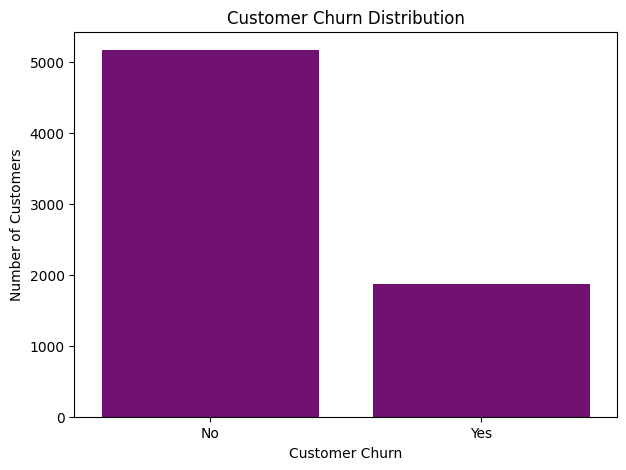

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [18]:

# GRAPH 1: Customer Churn Distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="Churn",color="purple")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

# Calculate churn counts and percentages
print(df_clean["Churn"].value_counts())

print("\nChurn Percentage:")
print(df_clean["Churn"].value_counts(normalize=True) * 100)


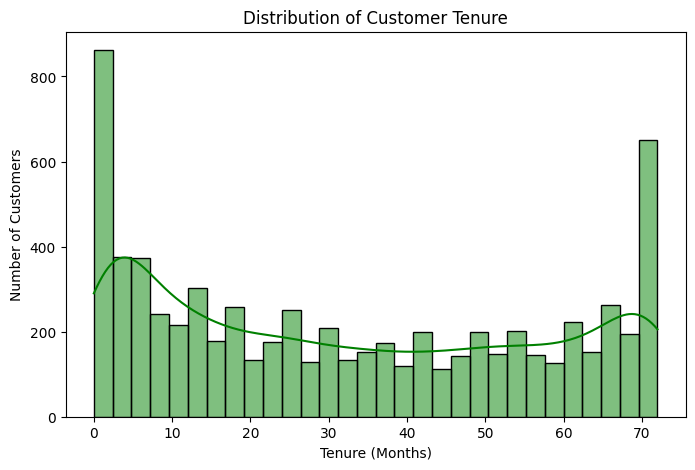

Tenure Summary:
count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64


In [17]:

# GRAPH 2: Customer Tenure Distribution

plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean, x="tenure", bins=30, kde=True,color="green")

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

# Statistical summary
print("Tenure Summary:")
print(df_clean["tenure"].describe())


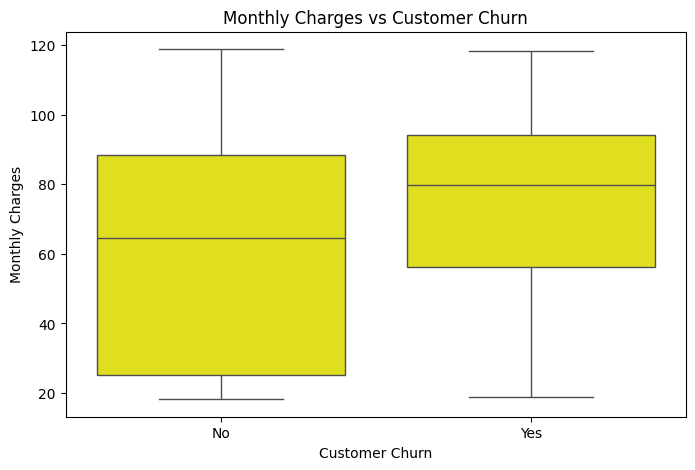

Average Monthly Charges:
Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


In [14]:

# GRAPH 3: Monthly Charges vs Churn

plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="Churn", y="MonthlyCharges",color="yellow")

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.show()

# Average monthly charges by churn
print("Average Monthly Charges:")
print(df_clean.groupby("Churn")["MonthlyCharges"].mean())


In [19]:

print("CUSTOMER CHURN ANALYSIS")
print(df_clean["Churn"].value_counts())

print("\nChurn percentages:")
print((df_clean["Churn"].value_counts(normalize=True) * 100).round(2))

print("\nTENURE ANALYSIS")
print(df_clean["tenure"].describe())

print("\nMONTHLY CHARGES ANALYSIS")
print(
    df_clean.groupby("Churn")["MonthlyCharges"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)


CUSTOMER CHURN ANALYSIS
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

TENURE ANALYSIS
count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

MONTHLY CHARGES ANALYSIS
        mean  median    min     max
Churn                              
No     61.27   64.43  18.25  118.75
Yes    74.44   79.65  18.85  118.35


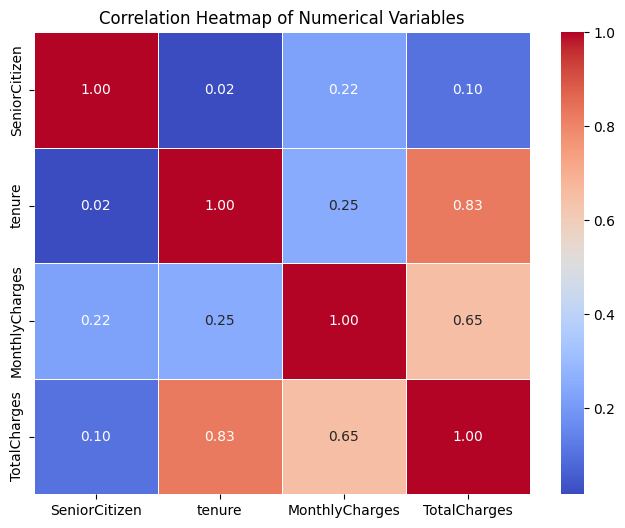

Correlation Matrix:
                SeniorCitizen  tenure  MonthlyCharges  TotalCharges
SeniorCitizen            1.00    0.02            0.22          0.10
tenure                   0.02    1.00            0.25          0.83
MonthlyCharges           0.22    0.25            1.00          0.65
TotalCharges             0.10    0.83            0.65          1.00


In [20]:

# WEEK 1: CORRELATION ANALYSIS

numerical_df = df_clean[
    ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
]

correlation = numerical_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

print("Correlation Matrix:")
print(correlation.round(2))
